# 05 - Evaluate ALL generated outputs together (Team One Sheep Army)

One notebook that re-scores **every generated image** in `sketchy_dataset_one_sketch/sdxl_runs` with the **same held-out metrics**, so runs can be compared side by side.

## What it finds in your Drive (checked on 26 Oct)
| Run folder | Contents | Arms |
|---|---|---|
| `sdxl_baseline_v1` | `manifest.jsonl` + 4 mode folders (768 px, 25 steps, 20 normal items) | `text`, `text_sketch`, `text_ref`, `text_sketch_ref` |
| `gated_v1` | `manifest_eval.jsonl`, `eval/`, `grid/`, `scores.json`, `gate.pt`, `results_table.csv` | gate version (`fixed`, `scheduled`, `gate`, `gate_guided`) |
| `router_v2` (the one that has files) | `manifest_eval.jsonl`, `eval/`, `grid/`, `heldout.csv`, `results_per_item.csv`, `paired_comparisons.csv`, `router.pt` | `fixed`, `scheduled`, `router`, `router_guided` |

Heads-up: `sdxl_runs` holds **four folders named `router_v2`**; only one has files, the other three are empty. The notebook skips folders with no manifest and tells you.
Also: notebook 04 sets `OUT` back to `router_v2` in its cell 3, so the run you called v3 was saved inside `router_v2`.

## Fairness notes (read before comparing)
- Runs differ in resolution (768 vs 640), steps (25 vs 20) and item sets. This notebook scores every image at the same size, but cross-run differences still mix model changes with setting changes. Compare arms **within** a run first; cross-run comparisons only use items that exist in both.
- Items are not independent: conflict variants share a base photo, so the bootstrap resamples **base photos**, not items.
- Metrics are re-implemented from notebook 04. Numbers can differ slightly from your saved `heldout.csv`; the cross-check cell shows how close they are.

In [1]:
# ---- 1. config + Drive ----
from google.colab import drive
drive.mount("/content/drive")
import os, glob, json, re, zipfile, time, gc, random
import numpy as np, pandas as pd

DRIVE_ROOT = "/content/drive/MyDrive/sketchy_dataset_one_sketch"
if not os.path.isdir(DRIVE_ROOT):
    hits = glob.glob("/content/drive/MyDrive/*/sketchy_dataset_one_sketch") + glob.glob("/content/drive/Shareddrives/*/sketchy_dataset_one_sketch")
    assert hits, "Cannot find sketchy_dataset_one_sketch. Set DRIVE_ROOT by hand."
    DRIVE_ROOT = hits[0]
RUNS_DIR = f"{DRIVE_ROOT}/sdxl_runs"
ZIP_PATH = f"{DRIVE_ROOT}/pilot_v1.zip"
CONFLICT_FILE = f"{DRIVE_ROOT}/metadata_with_conflicts.jsonl"
OUT_DIR = f"{RUNS_DIR}/_eval_all"
LOCAL_DATA = "/content/pilot_v1"
os.makedirs(OUT_DIR, exist_ok=True)
for p in (RUNS_DIR, ZIP_PATH, CONFLICT_FILE):
    assert os.path.exists(p), f"missing: {p}"

RES_SK = 640          # sketch/reference letterbox size used in notebook 04
EV = 256              # every generated image is scored at this size
RUN_DREAMSIM = False  # optional extra metric, see the last cells
print("DRIVE_ROOT:", DRIVE_ROOT)

Mounted at /content/drive
DRIVE_ROOT: /content/drive/MyDrive/sketchy_dataset_one_sketch


In [2]:
# ---- 2. discover runs and print an inventory ----
def read_jsonl(p):
    with open(p) as f:
        return [json.loads(l) for l in f if l.strip()]

def count_png(d):
    return sum(f.lower().endswith(".png") for _, _, fs in os.walk(d) for f in fs)

found = []
for root, dirs, files in os.walk(RUNS_DIR):
    if root.startswith(OUT_DIR):
        continue
    for fn, kind in (("manifest_eval.jsonl", "eval"), ("manifest.jsonl", "baseline")):
        if fn in files:
            found.append(dict(name=os.path.basename(root), dir=root, manifest=os.path.join(root, fn), kind=kind))
seen = {}
for r in found:
    seen[r["name"]] = seen.get(r["name"], 0) + 1
    r["label"] = r["name"] if seen[r["name"]] == 1 else f'{r["name"]}#{seen[r["name"]]}'
    r["n_rows"] = len(read_jsonl(r["manifest"]))
    r["n_png"] = count_png(r["dir"])
    r["extras"] = sorted(f for f in os.listdir(r["dir"]) if f.endswith((".csv", ".pt", ".json")))
inv = pd.DataFrame([{k: r[k] for k in ("label", "kind", "n_rows", "n_png", "extras")} for r in found])
print(inv.to_string(index=False))

# folders with no manifest (empty duplicates, smoke folders, ...)
skipped = []
for d1 in sorted(os.listdir(RUNS_DIR)):
    p1 = os.path.join(RUNS_DIR, d1)
    if os.path.isdir(p1) and d1 != "_eval_all" and not any(r["dir"] == p1 for r in found):
        skipped.append((d1, count_png(p1)))
print("\nfolders skipped (no manifest):", skipped)
if any(v > 1 for v in seen.values()):
    print("WARNING: repeated run names ->", {k: v for k, v in seen.items() if v > 1}, "(labelled #2, #3 ...)")
RUNS = found

           label     kind  n_rows  n_png                                                                              extras
sdxl_baseline_v1 baseline      80     80                                                                                  []
        gated_v1     eval     156    391                                           [gate.pt, results_table.csv, scores.json]
       router_v2     eval     240    493 [heldout.csv, paired_comparisons.csv, results_per_item.csv, router.pt, scores.json]

folders skipped (no manifest): [('router_v2 (1)', 0), ('router_v2 (2)', 0), ('router_v2 (3)', 0)]


In [3]:
# ---- 3. imports + data ----
!pip install -q lpips
import torch, cv2, lpips
import torch.nn.functional as F
from PIL import Image, ImageOps
from tqdm.auto import tqdm
import matplotlib.pyplot as plt
dev = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", dev)

if not glob.glob(f"{LOCAL_DATA}/**/metadata.jsonl", recursive=True):
    os.makedirs(LOCAL_DATA, exist_ok=True)
    with zipfile.ZipFile(ZIP_PATH) as z:
        z.extractall(LOCAL_DATA)
DATA_DIR = os.path.dirname(glob.glob(f"{LOCAL_DATA}/**/metadata.jsonl", recursive=True)[0])
meta_rows = read_jsonl(CONFLICT_FILE)
meta_by_id = {str(r["id"]): r for r in meta_rows}
print("pilot data:", DATA_DIR, "| metadata rows:", len(meta_rows))

device: cpu
pilot data: /content/pilot_v1 | metadata rows: 1000


In [4]:
# ---- 4. unified table of every generated image (pure python, no GPU) ----
KIND_OF = {"object_text_sketch": "sem", "color_text_ref": "color", "material_text_ref": "material", "appearance_ref_swap": "app"}
GROUP = dict(normal="normal", sem="object_conflict", color="attribute_conflict", material="attribute_conflict", app="ref_swap_conflict")

def tails_index(run_dir):
    idx = {1: {}, 2: {}, 3: {}}
    for rt, _, fs in os.walk(run_dir):
        for f in fs:
            if f.lower().endswith(".png"):
                p = os.path.join(rt, f)
                rel = os.path.relpath(p, run_dir).replace("\\", "/").split("/")
                for n in (1, 2, 3):
                    if len(rel) >= n:
                        idx[n].setdefault(tuple(rel[-n:]), []).append(p)
    return idx

def resolve_gen(gen, idx):
    # the manifest stores absolute /content/drive paths; if they do not exist, match the tail inside the run folder
    if not gen:
        return None
    if os.path.exists(gen):
        return gen
    parts = gen.replace("\\", "/").split("/")
    for n in (3, 2, 1):
        hits = idx[n].get(tuple(parts[-n:]), [])
        if len(hits) == 1:
            return hits[0]
    return None

def attr_from_meta(meta):
    if all(k in meta for k in ("ref_finish", "ref_material", "ref_colors")):
        return f"a {meta['ref_finish']} {meta['ref_material']} object in {meta['ref_colors']} colors"
    return None

def build_frame(runs):
    recs = []
    for r in runs:
        idx = tails_index(r["dir"])
        for m in read_jsonl(r["manifest"]):
            rid = str(m.get("id", m.get("key")))
            arm = m.get("mode", m.get("arm"))
            meta = meta_by_id.get(rid, {})
            ctype = meta.get("conflict_type")
            if "kind" in m:
                kind = m["kind"]
            elif ctype in (None, "none"):
                kind = "normal"
            else:
                kind = KIND_OF.get(ctype, "other")
            sk_cat = meta.get("category", m.get("category"))
            recs.append(dict(
                run=r["label"], run_kind=r["kind"], arm=arm, id=rid, seed=m.get("seed", 0),
                kind=kind, group=m.get("group") or GROUP.get(kind, kind),
                base=str(meta.get("original_id", rid)),
                caption=m.get("caption", meta.get("caption")),
                cap_category=meta.get("caption_category", sk_cat), sk_category=sk_cat,
                sketch=m.get("sketch", meta.get("sketch")), target=m.get("target", meta.get("target")),
                reference=m.get("reference", meta.get("reference")), attr=attr_from_meta(meta),
                gen_path=resolve_gen(m.get("generated"), idx)))
    return pd.DataFrame(recs)

M = build_frame(RUNS)
print("rows:", len(M))
print(M.groupby(["run", "arm"], sort=False).agg(rows=("id", "size"), items=("id", "nunique"), missing_images=("gen_path", lambda s: int(s.isna().sum()))))
print("\nkinds per run:"); print(M.groupby(["run", "kind"], sort=False)["id"].nunique().unstack(fill_value=0))
print("\nrows with no metadata match (attribute metrics will be NaN):", int(M.attr.isna().sum()))

rows: 476
                                  rows  items  missing_images
run              arm                                         
sdxl_baseline_v1 text               20     20               0
                 text_sketch        20     20               0
                 text_ref           20     20               0
                 text_sketch_ref    20     20               0
gated_v1         fixed              39     39               0
                 scheduled          39     39               0
                 gate               39     39               0
                 gate_guided        39     39               0
router_v2        fixed              60     30               0
                 scheduled          60     30               0
                 router             60     30               0
                 router_guided      60     30               0

kinds per run:
kind              normal  sem  color  material  app
run                                                
sd

In [5]:
# ---- 5. evaluation models (CLIP-B/32, DINOv2-small, LPIPS) ----
from transformers import CLIPVisionModelWithProjection, CLIPTextModelWithProjection, CLIPTokenizer, AutoModel
CLIPB = "openai/clip-vit-base-patch32"
cvis = CLIPVisionModelWithProjection.from_pretrained(CLIPB).to(dev).eval()
ctxt = CLIPTextModelWithProjection.from_pretrained(CLIPB).to(dev).eval()
ctok = CLIPTokenizer.from_pretrained(CLIPB)
dino = AutoModel.from_pretrained("facebook/dinov2-small").to(dev).eval()
LP = lpips.LPIPS(net="alex", verbose=False).to(dev).eval()

MEAN_C = torch.tensor([0.48145466, 0.4578275, 0.40821073], device=dev).view(1, 3, 1, 1)
STD_C = torch.tensor([0.26862954, 0.26130258, 0.27577711], device=dev).view(1, 3, 1, 1)
MEAN_I = torch.tensor([0.485, 0.456, 0.406], device=dev).view(1, 3, 1, 1)
STD_I = torch.tensor([0.229, 0.224, 0.225], device=dev).view(1, 3, 1, 1)

def to_t(pil):
    return torch.from_numpy(np.array(pil.convert("RGB"))).permute(2, 0, 1)[None].float().to(dev) / 255

@torch.no_grad()
def clip_img(x):
    x = F.interpolate(x, size=(224, 224), mode="bilinear", align_corners=False)
    return F.normalize(cvis(pixel_values=(x - MEAN_C) / STD_C).image_embeds, dim=-1)

_txt_cache = {}
@torch.no_grad()
def clip_txt(s):
    if s not in _txt_cache:
        tk = ctok([s], padding="max_length", max_length=77, truncation=True, return_tensors="pt").to(dev)
        _txt_cache[s] = F.normalize(ctxt(input_ids=tk.input_ids, attention_mask=tk.attention_mask).text_embeds, dim=-1)
    return _txt_cache[s]

@torch.no_grad()
def dino_img(x):
    x = F.interpolate(x, size=(224, 224), mode="bilinear", align_corners=False)
    return F.normalize(dino(pixel_values=(x - MEAN_I) / STD_I).last_hidden_state[:, 0], dim=-1)

def letterbox(im, size, fill):
    im = ImageOps.contain(im, (size, size), Image.LANCZOS)
    c = Image.new("RGB", (size, size), fill)
    c.paste(im, ((size - im.width) // 2, (size - im.height) // 2))
    return c

def prep_sketch(path):      # white lines on black, same as notebook 04
    im = Image.open(path).convert("L")
    if np.array(im).mean() > 127:
        im = ImageOps.invert(im)
    return letterbox(im.convert("RGB"), RES_SK, (0, 0, 0))

def prep_ref(path):
    return letterbox(Image.open(path).convert("RGB"), RES_SK, (127, 127, 127))

def thin_np(sk_pil, size):
    t = torch.from_numpy(np.array(sk_pil.convert("L"))).float()[None, None] / 255
    t = F.interpolate(t, size=(size, size), mode="area")[0, 0].numpy()
    return t > 0.35 * t.max()

def color_hist(px, bins=6):
    q = np.clip(px // (256 // bins), 0, bins - 1).astype(int)
    h = np.bincount(q[:, 0] * bins * bins + q[:, 1] * bins + q[:, 2], minlength=bins ** 3).astype(float)
    return h / (np.linalg.norm(h) + 1e-9)

def ref_object_pixels(ref_pil):
    r = np.array(ref_pil.resize((256, 256))).astype(float)
    border = np.concatenate([r[:6].reshape(-1, 3), r[-6:].reshape(-1, 3), r[:, :6].reshape(-1, 3), r[:, -6:].reshape(-1, 3)])
    m = np.linalg.norm(r - np.median(border, 0), axis=-1) > 30
    return r[m] if m.sum() > 200 else None

def ok(v):
    return isinstance(v, str) and v != ""

def dp(p):
    full = os.path.join(DATA_DIR, p) if ok(p) else None
    return full if full and os.path.exists(full) else None

_base = {}
@torch.no_grad()
def base_cache(row):
    k = row["id"]
    if k in _base:
        return _base[k]
    B = dict(thin=None, ref_dino=None, ref_pix=None, tgt=None, tgt_clip=None, tgt_dino=None)
    sp, rp, tp = dp(row["sketch"]), dp(row["reference"]), dp(row["target"])
    if sp: B["thin"] = thin_np(prep_sketch(sp), EV)
    if rp:
        ref = prep_ref(rp)
        B["ref_dino"] = dino_img(to_t(ref)); B["ref_pix"] = ref_object_pixels(ref)
    if tp:
        t = Image.open(tp).convert("RGB")
        B["tgt"] = to_t(t.resize((EV, EV), Image.BICUBIC))
        B["tgt_clip"] = clip_img(to_t(t)); B["tgt_dino"] = dino_img(to_t(t))
    _base[k] = B
    return B

@torch.no_grad()
def score_one(row):
    B = base_cache(row)
    img = Image.open(row["gen_path"]).convert("RGB")
    out = {}
    g = np.array(img.resize((EV, EV)).convert("L"))
    E = cv2.Canny(g, 80, 160) > 0
    if B["thin"] is not None:
        thin = B["thin"]; k = np.ones((7, 7), np.uint8)
        Ed = cv2.dilate(E.astype(np.uint8), k) > 0; Td = cv2.dilate(thin.astype(np.uint8), k) > 0
        out["edge_recall"] = float((thin & Ed).sum() / max(thin.sum(), 1))
        out["edge_precision"] = float((E & Td).sum() / max(E.sum(), 1))
        out["edge_iou"] = float((Ed & Td).sum() / max((Ed | Td).sum(), 1))
    x = to_t(img)
    ci = clip_img(x)
    if ok(row["cap_category"]):
        out["sem_text"] = float((ci * clip_txt(f"a photo of a {row['cap_category']}")).sum())
    if ok(row["sk_category"]):
        out["sem_sketch"] = float((ci * clip_txt(f"a photo of a {row['sk_category']}")).sum())
    if "sem_text" in out and "sem_sketch" in out:
        out["sem_margin"] = out["sem_text"] - out["sem_sketch"]
    if ok(row["caption"]):
        out["clip_t"] = float((ci * clip_txt(row["caption"])).sum())
    if ok(row["attr"]):
        out["attr_B"] = float((ci * clip_txt(row["attr"])).sum())
    if B["ref_dino"] is not None:
        out["dino_ref"] = float((dino_img(x) * B["ref_dino"]).sum())
    if B["thin"] is not None and B["ref_pix"] is not None:
        ys, xs = np.where(B["thin"])
        if len(ys):
            y0, y1 = max(ys.min() - 12, 0), min(ys.max() + 12, EV - 1)
            x0, x1 = max(xs.min() - 12, 0), min(xs.max() + 12, EV - 1)
            gp = np.array(img.resize((EV, EV)).convert("RGB"))[y0:y1 + 1, x0:x1 + 1].reshape(-1, 3)
            out["color_match"] = float(color_hist(gp) @ color_hist(B["ref_pix"]))
    if B["tgt"] is not None:
        xs_ = to_t(img.resize((EV, EV), Image.BICUBIC))
        out["lpips_tgt"] = float(LP(xs_ * 2 - 1, B["tgt"] * 2 - 1).mean())
        out["dino_tgt"] = float((dino_img(x) * B["tgt_dino"]).sum())
        out["clipI_tgt"] = float((ci * B["tgt_clip"]).sum())
    return out
print("models ready")

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:138: UserWarning: 
Error while fetching `HF_TOKEN` secret value from your vault: 'Requesting secret HF_TOKEN timed out. Secrets can only be fetched when running from the Colab UI.'.
  warnings.warn(f"\nError while fetching `HF_TOKEN` secret value from your vault: '{str(e)}'.")


config.json:   0%|          | 0.00/4.19k [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  605MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/200 [00:00<?, ?it/s]

...

Loading weights:   0%|          | 0/223 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=AlexNet_Weights.IMAGENET1K_V1`. You can also use `weights=AlexNet_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


Downloading: "https://download.pytorch.org/models/alexnet-owt-7be5be79.pth" to /root/.cache/torch/hub/checkpoints/alexnet-owt-7be5be79.pth


100%|██████████| 233M/233M [00:02<00:00, 119MB/s] 


models ready


In [6]:
# ---- 6. score every image (resumable; saved to Drive) ----
METRIC_FILE = f"{OUT_DIR}/all_metrics.csv"
M["key"] = M.run + "|" + M.arm.astype(str) + "|" + M.id + "|" + M.seed.astype(str)
done = pd.read_csv(METRIC_FILE) if os.path.exists(METRIC_FILE) else pd.DataFrame()
done_keys = set(done["key"]) if len(done) else set()
todo = M[M.gen_path.notna() & ~M.key.isin(done_keys)]
print(f"already scored: {len(done_keys)} | to score now: {len(todo)} | images missing on disk: {int(M.gen_path.isna().sum())}")

new, errors = [], []
for i, (_, row) in enumerate(tqdm(todo.iterrows(), total=len(todo), desc="scoring")):
    try:
        new.append(dict(key=row["key"], **score_one(row)))
    except Exception as e:
        errors.append((row["key"], repr(e)[:150]))
    if (i + 1) % 50 == 0:
        pd.concat([done, pd.DataFrame(new)], ignore_index=True).to_csv(METRIC_FILE, index=False)
allm = pd.concat([done, pd.DataFrame(new)], ignore_index=True).drop_duplicates("key")
allm.to_csv(METRIC_FILE, index=False)
print("scored total:", len(allm), "| errors:", len(errors))
for e in errors[:10]:
    print("  ", e)
H = M.merge(allm, on="key", how="inner")
METRICS = ["edge_recall", "edge_precision", "edge_iou", "sem_text", "sem_sketch", "sem_margin", "clip_t", "attr_B", "dino_ref", "color_match", "lpips_tgt", "dino_tgt", "clipI_tgt"]
METRICS = [c for c in METRICS if c in H.columns]
# one row per (run, arm, item): average the seeds first
Hi = H.groupby(["run", "arm", "id", "kind", "group", "base"], as_index=False, sort=False)[METRICS].mean()
Hi.to_csv(f"{OUT_DIR}/per_item_all.csv", index=False)
print("items scored:", len(Hi))

already scored: 0 | to score now: 476 | images missing on disk: 0


scoring:   0%|          | 0/476 [00:00<?, ?it/s]

scored total: 476 | errors: 0
items scored: 356


In [7]:
# ---- 7. summary tables (mean +- standard error over items) ----
def summarize(Hi, cols, groups=None):
    d = Hi if groups is None else Hi[Hi.group.isin(groups)]
    g = d.groupby(["group", "run", "arm"], sort=False)
    out = g[cols].mean().round(3).astype(str) + " +-" + g[cols].sem().round(3).astype(str)
    out.insert(0, "n", g.size())
    return out

SETS = {
 "GEOMETRY (sketch): edge recall / precision / IoU, higher = follows sketch": ["edge_recall", "edge_precision", "edge_iou"],
 "SEMANTICS (text): CLIP-B/32 to caption object; sem_margin > 0 = reads as caption object": ["sem_text", "sem_sketch", "sem_margin", "clip_t"],
 "APPEARANCE (reference): colour match, DINO to reference, CLIP to attribute phrase": ["color_match", "dino_ref", "attr_B"],
 "FIDELITY to ground-truth photo (normal items only; lpips lower is better)": ["lpips_tgt", "dino_tgt", "clipI_tgt"],
}
pd.set_option("display.width", 250); pd.set_option("display.max_columns", 30)
for title, cols in SETS.items():
    cols = [c for c in cols if c in Hi.columns]
    if not cols: continue
    print("\n==", title, "==")
    print(summarize(Hi, cols, ["normal"] if "FIDELITY" in title else None).to_string())


== GEOMETRY (sketch): edge recall / precision / IoU, higher = follows sketch ==
                                                      n    edge_recall edge_precision       edge_iou
group              run              arm                                                             
normal             sdxl_baseline_v1 text             20  0.666 +-0.056  0.171 +-0.024   0.145 +-0.02
                                    text_sketch      20  0.981 +-0.007  0.398 +-0.061  0.348 +-0.051
                                    text_ref         20  0.398 +-0.049   0.257 +-0.03   0.169 +-0.02
                                    text_sketch_ref  20  0.964 +-0.012  0.735 +-0.064  0.641 +-0.054
                   gated_v1         fixed            20  0.954 +-0.023  0.715 +-0.058  0.623 +-0.052
                                    scheduled        20  0.958 +-0.018   0.432 +-0.07  0.379 +-0.057
                                    gate             20  0.971 +-0.006  0.439 +-0.069  0.382 +-0.057
          

In [8]:
# ---- 8. paired comparisons with a base-photo (cluster) bootstrap ----
def paired_boot(Hi, a, b, metric, groups=None, n_boot=5000, seed=0):
    # a, b = (run, arm); difference = a - b on the items both have; resamples BASE PHOTOS, not items
    A = Hi[(Hi.run == a[0]) & (Hi.arm == a[1])]
    B = Hi[(Hi.run == b[0]) & (Hi.arm == b[1])]
    if groups is not None:
        A, B = A[A.group.isin(groups)], B[B.group.isin(groups)]
    m = A.merge(B, on="id", suffixes=("_a", "_b"))
    if metric + "_a" not in m.columns:
        return None
    dd = pd.DataFrame({"d": (m[metric + "_a"] - m[metric + "_b"]).values, "base": m["base_a"].values}).dropna()
    if len(dd) < 3:
        return None
    g = dd.groupby("base")["d"].agg(["sum", "count"])
    sums, counts = g["sum"].values, g["count"].values
    idx = np.random.default_rng(seed).integers(0, len(g), size=(n_boot, len(g)))
    means = sums[idx].sum(1) / counts[idx].sum(1)
    lo, hi = np.percentile(means, [2.5, 97.5])
    d = dd["d"].values
    return dict(comparison=f"{a[0]}:{a[1]} - {b[0]}:{b[1]}", metric=metric, n_items=len(d), n_bases=len(g),
                mean_diff=round(float(d.mean()), 4), ci_low=round(float(lo), 4), ci_high=round(float(hi), 4),
                significant="yes" if (lo > 0 or hi < 0) else "no", wins=f"{int((d > 0).sum())}/{len(d)}")

# within-run pairs: every arm vs the first arm, and each arm vs the one before it
pairs = []
for run, d in Hi.groupby("run", sort=False):
    arms = list(dict.fromkeys(d.arm))
    for i in range(1, len(arms)):
        for pr in ((arms[i], arms[0]), (arms[i], arms[i - 1])):
            if (run, pr[0], run, pr[1]) not in [(p[0][0], p[0][1], p[1][0], p[1][1]) for p in pairs]:
                pairs.append(((run, pr[0]), (run, pr[1])))

# cross-run pairs (EDIT ME). Only normal items that both runs contain are compared.
CROSS_PAIRS = []
runs_here = list(dict.fromkeys(Hi.run))
base_run = next((r for r in runs_here if "baseline" in r), None)
other_runs = [r for r in runs_here if r != base_run and Hi[Hi.run == r].arm.eq("fixed").any()]
if base_run and other_runs:
    CROSS_PAIRS = [((r, "fixed"), (base_run, "text_sketch_ref")) for r in other_runs]

rows = []
for a, b in pairs:
    for met in METRICS:
        out = paired_boot(Hi, a, b, met, groups=None)
        if out: out["items"] = "all"; rows.append(out)
for a, b in CROSS_PAIRS:
    for met in METRICS:
        out = paired_boot(Hi, a, b, met, groups=["normal"])
        if out: out["items"] = "normal (cross-run, settings differ)"; rows.append(out)
PT = pd.DataFrame(rows)
PT.to_csv(f"{OUT_DIR}/paired_all.csv", index=False)
print("comparisons:", len(PT), "| significant:", int((PT.significant == "yes").sum()))
print("\nReading it: an upgrade helps only if the CI excludes 0 (significant = yes). With ~20 base photos, expect wide CIs.")
SIG = PT[PT.significant == "yes"].sort_values(["comparison", "metric"])
print(SIG[["comparison", "items", "metric", "n_items", "n_bases", "mean_diff", "ci_low", "ci_high", "wins"]].to_string(index=False))

comparisons: 221 | significant: 101

Reading it: an upgrade helps only if the CI excludes 0 (significant = yes). With ~20 base photos, expect wide CIs.
                                                  comparison items         metric  n_items  n_bases  mean_diff  ci_low  ci_high  wins
                              gated_v1:gate - gated_v1:fixed   all         attr_B       39       20    -0.0181 -0.0294  -0.0077  8/39
                              gated_v1:gate - gated_v1:fixed   all         clip_t       39       20     0.0201  0.0066   0.0356 28/39
                              gated_v1:gate - gated_v1:fixed   all       dino_ref       39       20    -0.0664 -0.0987  -0.0416  8/39
                              gated_v1:gate - gated_v1:fixed   all       edge_iou       39       20    -0.2460 -0.3463  -0.1452  5/39
                              gated_v1:gate - gated_v1:fixed   all edge_precision       39       20    -0.2790 -0.4024  -0.1530  8/39
                              gated_v1:gate 

In [9]:
# ---- 9. which items do the runs share? (needed for any cross-run claim) ----
ids_by_run = {r: set(Hi[(Hi.run == r) & (Hi.group == "normal")].id) for r in runs_here}
print("normal items per run:", {r: len(s) for r, s in ids_by_run.items()})
for i, r1 in enumerate(runs_here):
    for r2 in runs_here[i + 1:]:
        print(f"  shared normal items {r1} & {r2}: {len(ids_by_run[r1] & ids_by_run[r2])}")
print("\nbase photos per run:", {r: Hi[Hi.run == r].base.nunique() for r in runs_here})

normal items per run: {'sdxl_baseline_v1': 20, 'gated_v1': 20, 'router_v2': 12}
  shared normal items sdxl_baseline_v1 & gated_v1: 20
  shared normal items sdxl_baseline_v1 & router_v2: 12
  shared normal items gated_v1 & router_v2: 12

base photos per run: {'sdxl_baseline_v1': 20, 'gated_v1': 20, 'router_v2': 12}


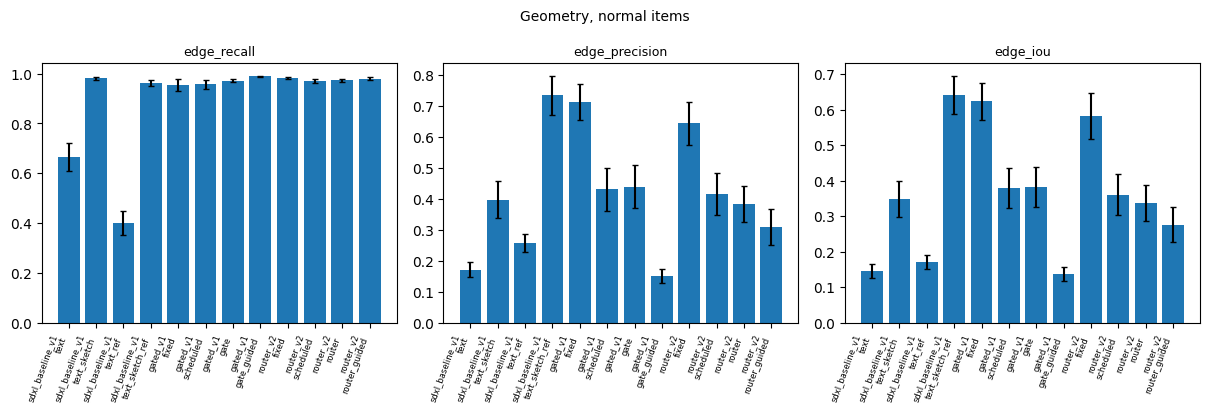

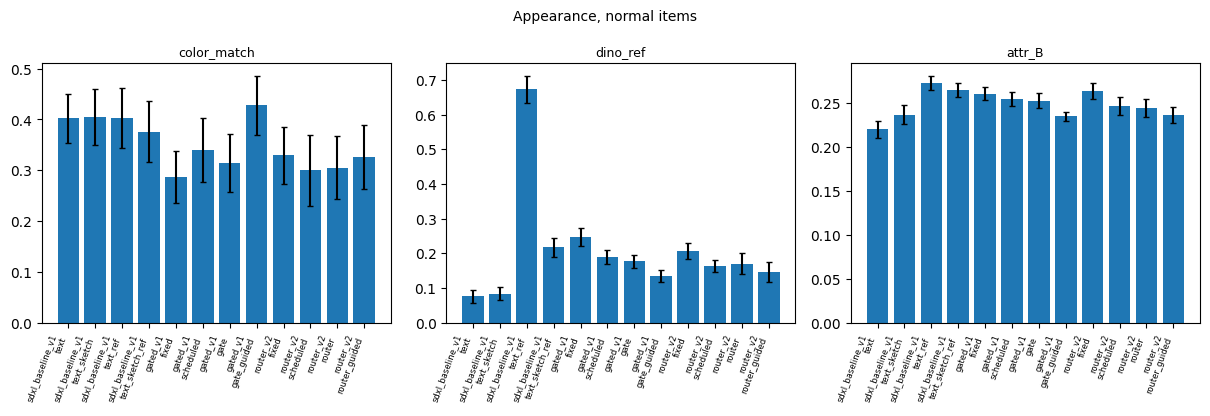

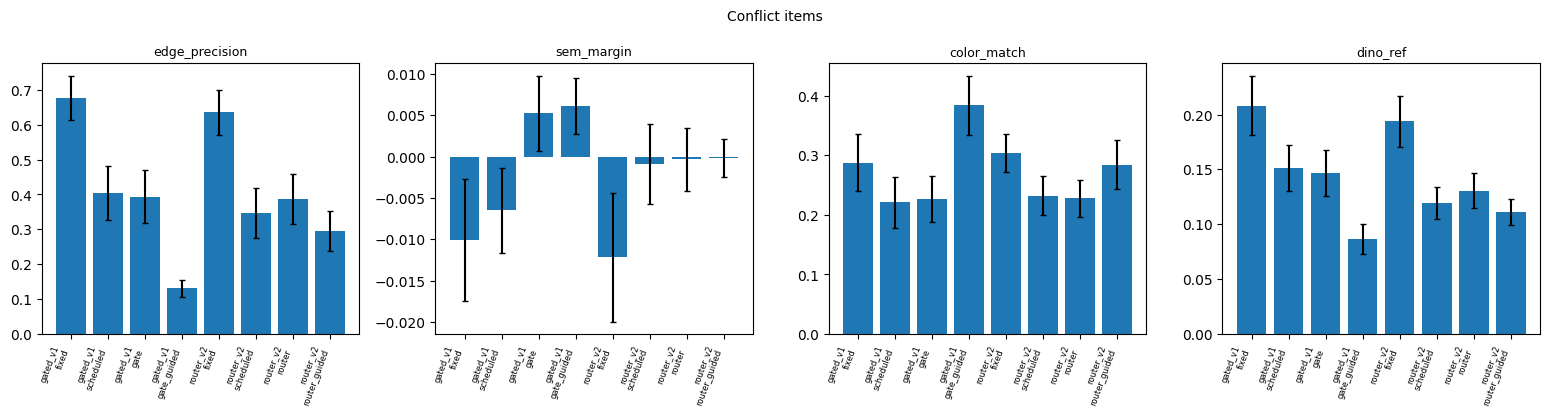

In [10]:
# ---- 10. plots ----
def plot_metrics(Hi, metrics, groups, title, fname):
    d = Hi[Hi.group.isin(groups)].copy()
    d["label"] = d.run + "\n" + d.arm.astype(str)
    order = list(dict.fromkeys(d.label))
    fig, axes = plt.subplots(1, len(metrics), figsize=(3.4 * len(metrics) + 2, 4.2), squeeze=False)
    for ax, m in zip(axes[0], metrics):
        g = d.groupby("label", sort=False)[m]
        mean, sem = g.mean().reindex(order), g.sem().reindex(order)
        ax.bar(range(len(order)), mean.values, yerr=sem.values, capsize=2)
        ax.set_xticks(range(len(order))); ax.set_xticklabels(order, rotation=70, ha="right", fontsize=6)
        ax.set_title(m, fontsize=9)
    fig.suptitle(title, fontsize=10); fig.tight_layout()
    fig.savefig(f"{OUT_DIR}/{fname}", dpi=130); plt.show()

plot_metrics(Hi, [c for c in ("edge_recall", "edge_precision", "edge_iou") if c in Hi], ["normal"], "Geometry, normal items", "plot_geometry_normal.png")
plot_metrics(Hi, [c for c in ("color_match", "dino_ref", "attr_B") if c in Hi], ["normal"], "Appearance, normal items", "plot_appearance_normal.png")
conf_groups = [g for g in Hi.group.unique() if g != "normal"]
if conf_groups:
    plot_metrics(Hi, [c for c in ("edge_precision", "sem_margin", "color_match", "dino_ref") if c in Hi], conf_groups, "Conflict items", "plot_conflict.png")

In [11]:
# ---- 11. contact sheet: same items across every run/arm ----
CONTACT_IDS = None      # e.g. ["0027", "0088"]; None = auto (items present in the most run/arm combos)
N_SHOW = 4
combos = list(dict.fromkeys(zip(M.run, M.arm.astype(str))))
if CONTACT_IDS is None:
    freq = M.groupby("id").apply(lambda d: len(set(zip(d.run, d.arm.astype(str)))))
    CONTACT_IDS = list(freq.sort_values(ascending=False, kind="stable").index[:N_SHOW])
fig, ax = plt.subplots(len(CONTACT_IDS), 2 + len(combos), figsize=(2.1 * (2 + len(combos)), 2.3 * len(CONTACT_IDS)), squeeze=False)
for r_, iid in enumerate(CONTACT_IDS):
    rows_i = M[M.id == iid]
    first = rows_i.iloc[0]
    sp, rp = dp(first["sketch"]), dp(first["reference"])
    ax[r_, 0].imshow(prep_sketch(sp) if sp else np.zeros((8, 8, 3))); ax[r_, 0].set_title(f"{iid} sketch", fontsize=6)
    ax[r_, 1].imshow(prep_ref(rp) if rp else np.zeros((8, 8, 3))); ax[r_, 1].set_title("reference", fontsize=6)
    for c, (run, arm) in enumerate(combos):
        a = ax[r_, 2 + c]
        hit = rows_i[(rows_i.run == run) & (rows_i.arm.astype(str) == arm) & rows_i.gen_path.notna()]
        if len(hit): a.imshow(Image.open(hit.iloc[0]["gen_path"]).convert("RGB"))
        if r_ == 0: a.set_title(f"{run}\n{arm}", fontsize=5)
for a in ax.ravel(): a.axis("off")
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/contact_all.png", dpi=110); plt.show()

Output hidden; open in https://colab.research.google.com to view.

In [12]:
# ---- 12. cross-check against what your earlier notebooks saved ----
for r in RUNS:
    p = os.path.join(r["dir"], "results_per_item.csv")
    if os.path.exists(p):
        old = pd.read_csv(p)
        old = old.rename(columns={"key": "id"})
        old = old.groupby(["id", "arm"], as_index=False).mean(numeric_only=True)
        mine = Hi[Hi.run == r["label"]][["id", "arm"] + METRICS]
        j = old.merge(mine, on=["id", "arm"], suffixes=("_old", "_new"))
        print(f"\n{r['label']}: matched {len(j)} item/arm rows against results_per_item.csv")
        res = []
        for c in METRICS:
            if c + "_old" in j.columns and j[[c + "_old", c + "_new"]].dropna().shape[0] > 3:
                v = j[[c + "_old", c + "_new"]].dropna()
                res.append((c, round(float(np.corrcoef(v.iloc[:, 0], v.iloc[:, 1])[0, 1]), 3), round(float((v.iloc[:, 0] - v.iloc[:, 1]).abs().mean()), 4)))
        print(pd.DataFrame(res, columns=["metric", "pearson_r", "mean_abs_diff"]).to_string(index=False))
    p2 = os.path.join(r["dir"], "results_table.csv")
    if os.path.exists(p2):
        t = pd.read_csv(p2, index_col=[0, 1])
        t.columns = [c.replace("\\", "") for c in t.columns]
        print(f"\n{r['label']}: results_table.csv (different metrics: clip_t, attr, clip_i, dino_i, recall, outside)")
        print(t.to_string())


gated_v1: results_table.csv (different metrics: clip_t, attr, clip_i, dino_i, recall, outside)
                      clip_t   attr  clip_i  dino_i  recall  outside
normal   fixed         0.232  0.200   0.661   0.379   0.141    0.028
         scheduled     0.251  0.203   0.672   0.370   0.138    0.054
         gate          0.259  0.193   0.681   0.404   0.146    0.058
         gate_guided   0.232  0.188   0.625   0.226   0.167    0.129
sem      fixed         0.136  0.197   0.549   0.164   0.135    0.042
         scheduled     0.152  0.168   0.532   0.134   0.144    0.072
         gate          0.202  0.181   0.511   0.104   0.130    0.067
         gate_guided   0.184  0.178   0.489   0.098   0.158    0.138
color    fixed         0.238  0.200   0.648   0.380   0.193    0.029
         scheduled     0.251  0.204   0.643   0.337   0.176    0.046
         gate          0.257  0.190   0.645   0.387   0.191    0.042
         gate_guided   0.230  0.180   0.583   0.225   0.180    0.120
materia

In [13]:
# ---- 13. optional DreamSim (off by default) ----
if RUN_DREAMSIM:
    try:
        import subprocess, sys
        subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'dreamsim'], check=True)
        from dreamsim import dreamsim
        ds_model, ds_pre = dreamsim(pretrained=True, device=dev)
        vals = []
        for _, row in tqdm(M[M.gen_path.notna() & (M.group == "normal")].iterrows()):
            tp = dp(row["target"])
            if not tp: continue
            with torch.no_grad():
                d = ds_model(ds_pre(Image.open(row["gen_path"]).convert("RGB")).to(dev), ds_pre(Image.open(tp).convert("RGB")).to(dev))
            vals.append(dict(key=row["key"], dreamsim_tgt=float(d)))
        ds_df = pd.DataFrame(vals); ds_df.to_csv(f"{OUT_DIR}/dreamsim.csv", index=False)
        H2 = M.merge(ds_df, on="key")
        print(H2.groupby(["run", "arm"], sort=False)["dreamsim_tgt"].agg(["mean", "sem", "count"]).round(3))
    except Exception as e:
        print("DreamSim skipped:", repr(e)[:200])
else:
    print("DreamSim off. FID with ~20-30 images per arm is not reliable, so it is not computed here.")

DreamSim off. FID with ~20-30 images per arm is not reliable, so it is not computed here.


In [14]:
# ---- 14. export for the report ----
S = summarize(Hi, [c for c in METRICS if c in Hi.columns])
S.to_csv(f"{OUT_DIR}/summary_all.csv")
num = Hi[Hi.group == "normal"].groupby(["run", "arm"], sort=False)[METRICS].mean().round(3)
try:
    open(f"{OUT_DIR}/table_normal.tex", "w").write(num.to_latex(caption="Held-out metrics on normal items (mean over items).", label="tab:allruns", float_format="%.3f"))
except Exception as e:
    print("latex export skipped:", repr(e)[:150])
print(num.to_string())
print("\nsaved to", OUT_DIR, ":", sorted(os.listdir(OUT_DIR)))

                                  edge_recall  edge_precision  edge_iou  sem_text  sem_sketch  sem_margin  clip_t  attr_B  dino_ref  color_match  lpips_tgt  dino_tgt  clipI_tgt
run              arm                                                                                                                                                            
sdxl_baseline_v1 text                   0.666           0.171     0.145     0.296       0.296         0.0   0.327   0.220     0.076        0.402      0.680     0.527      0.743
                 text_sketch            0.981           0.398     0.348     0.301       0.301         0.0   0.315   0.237     0.083        0.404      0.669     0.478      0.735
                 text_ref               0.398           0.257     0.169     0.227       0.227         0.0   0.210   0.273     0.673        0.403      0.719     0.105      0.535
                 text_sketch_ref        0.964           0.735     0.641     0.291       0.291         0.0   0.282  